# Sampling Distributions: Sample Mean and Sample Proportion

## Learning goals
- Distinguish population, sample, and sampling distributions.
- Understand the sampling distribution of the sample mean (SDSM) and sample proportion (SDSP).
- Calculate standard errors, use the Central Limit Theorem (CLT), and construct confidence intervals.
- Choose critical values and understand when the *t*-distribution and degrees of freedom apply.
- Understand the finite population correction (FPC), inference conditions, and simulations.

**Dataset:** `StudentsPerformance.csv`, using the file path supplied. We use `math score` for the mean and `gender == "female"` for a sample proportion.

**Important:** The *t*-distribution is used for inference about a population mean when its standard deviation is unknown. It is not the usual method for inference about a population proportion.

## 1. Load and prepare the dataset

If the file is stored elsewhere, change `file_path`. The dataset is a collection of student records; do not automatically assume it represents every student or college.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

file_path = r"C:\Users\WIN 10\Documents\stats and probability\StudentsPerformance.csv"
df = pd.read_csv(file_path)

math_scores = df["math score"].dropna().astype(float)
gender = df["gender"].dropna().astype(str).str.strip().str.lower()
is_female = (gender == "female").astype(int)

print("Dataset shape:", df.shape)
display(df.head())
print("Valid math scores:", len(math_scores))
print("Valid gender records:", len(is_female))
print("Female count:", int(is_female.sum()))
print("Female sample proportion:", round(is_female.mean(), 4))

Dataset shape: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


Valid math scores: 1000
Valid gender records: 1000
Female count: 518
Female sample proportion: 0.518


## 2. Population distribution vs. sample distribution vs. sampling distribution

**Population distribution:** The distribution of individual values for every member of the population of interest. Population parameters include the true mean $\mu$ and true proportion $p$.

**Sample distribution:** The distribution of individual observations in one collected sample. Here, the histogram of `math score` shows the sample distribution in the available dataset.

**Sampling distribution:** The distribution of a statistic—such as a sample mean $\bar{X}$ or sample proportion $\hat{p}$—across many repeated samples of the same size drawn using the same method.

**Memory aid**
- Population distribution = all individual values in the target population.
- Sample distribution = individual values in one sample.
- Sampling distribution = a statistic calculated from many samples.

The available dataset lets us plot a sample distribution. We do not know the true population distribution unless we have data for the whole target population.

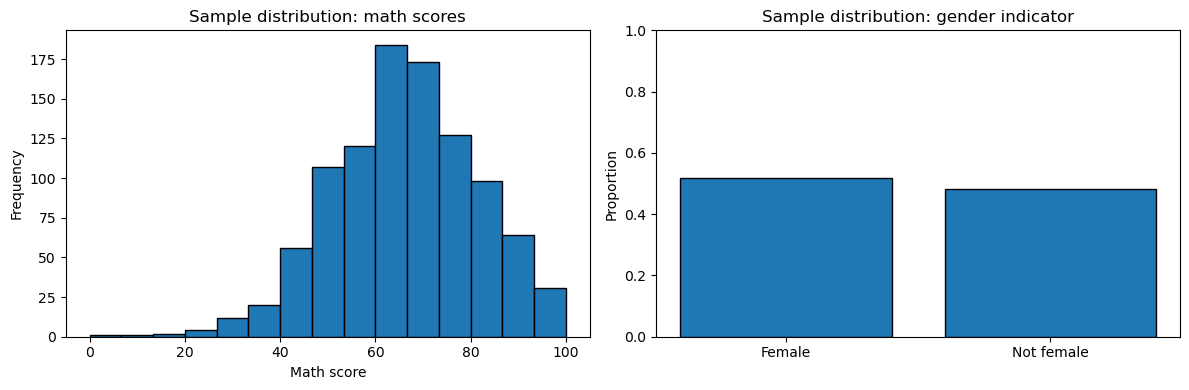

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(math_scores, bins=15, edgecolor="black")
axes[0].set(title="Sample distribution: math scores", xlabel="Math score", ylabel="Frequency")
axes[1].bar(["Female", "Not female"], [is_female.mean(), 1-is_female.mean()], edgecolor="black")
axes[1].set(title="Sample distribution: gender indicator", ylabel="Proportion", ylim=(0, 1))
plt.tight_layout()
plt.show()

These are distributions of individual records, **not sampling distributions**. To create a sampling distribution, we must repeatedly sample and calculate a statistic each time.

## 3.Sampling Distribution of Sample Mean

The sample mean is:

$$
\bar{X} = \frac{X_1 + X_2 + \cdots + X_n}{n}
$$

The **Sampling Distribution of the Sample Mean (SDSM)** is the distribution of sample means across repeated samples of the same size.

**Intuition:** Repeatedly select 40 students and calculate the average math score for each group. The averages may be 68, 71, 69, and so on because each group contains different students. The distribution of these averages is the SDSM.

Under random sampling, the center is:

$$
\mu_{\bar{X}} = \mu
$$

For independent observations, its standard error is:

$$
SE_{\bar{X}} = \frac{\sigma}{\sqrt{n}}
$$

If the population is normal, the sample mean is normally distributed for any sample size under the usual assumptions.

For a non-normal population, the **Central Limit Theorem (CLT)** states that the SDSM is approximately normal for sufficiently large samples, under suitable conditions.

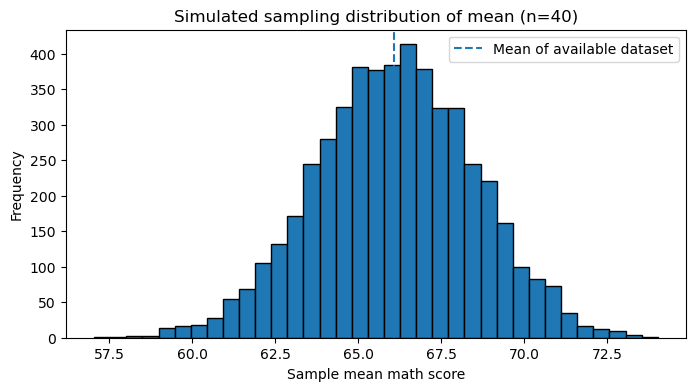

Dataset mean: 66.089
Mean of simulated means: 66.107
SD of simulated means: 2.398


In [8]:
rng = np.random.default_rng(42)
n_mean = 40
repetitions = 5000
scores = math_scores.to_numpy()

mean_samples = np.array([
    rng.choice(scores, size=n_mean, replace=True).mean()
    for _ in range(repetitions)
])

plt.figure(figsize=(8, 4))
plt.hist(mean_samples, bins=35, edgecolor="black")
plt.axvline(scores.mean(), linestyle="--", label="Mean of available dataset")
plt.title(f"Simulated sampling distribution of mean (n={n_mean})")
plt.xlabel("Sample mean math score")
plt.ylabel("Frequency")
plt.legend()
plt.show()

print(f"Dataset mean: {scores.mean():.3f}")
print(f"Mean of simulated means: {mean_samples.mean():.3f}")
print(f"SD of simulated means: {mean_samples.std(ddof=1):.3f}")

## 4. Sampling Distribution of the Sample Proportion (SDSP)

The sample proportion is:

$$
\hat{p} = \frac{x}{n}
$$

where:
- $x$ is the number of observations with the characteristic (success).
- $n$ is the sample size.

The **SDSP** is the distribution of sample proportions ($\hat{p}$) across repeated samples of the same size.

**Intuition:** Define “success” as a record where `gender == "female"`. Repeated samples of 100 records might produce proportions such as 0.49, 0.53, and 0.47. The distribution of these fractions is the SDSP.

### Center and Standard Error

The center (mean) of the sampling distribution is:

$$
\mu_{\hat{p}} = p
$$

The standard error is:

$$
SE_{\hat{p}} = \sqrt{\frac{p(1-p)}{n}}
$$

When the population proportion ($p$) is unknown, estimate the standard error using the sample proportion ($\hat{p}$):

$$
\widehat{SE}_{\hat{p}} = \sqrt{\frac{\hat{p}(1-\hat{p})}{n}}
$$

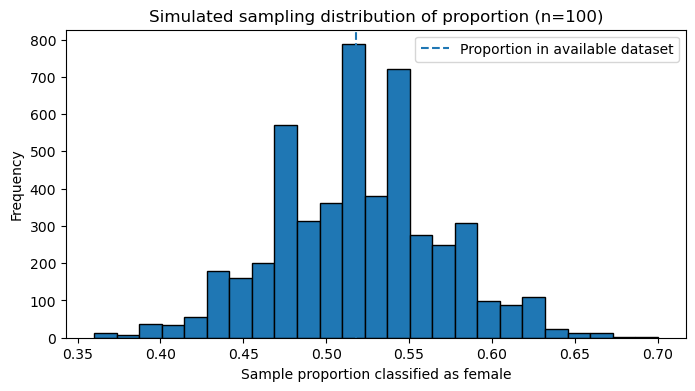

Dataset proportion: 0.5180
Mean of simulated proportions: 0.5195
SD of simulated proportions: 0.0504


In [10]:
rng = np.random.default_rng(123)
female = is_female.to_numpy()
n_prop = 100
repetitions_prop = 5000

prop_samples = np.array([
    rng.choice(female, size=n_prop, replace=True).mean()
    for _ in range(repetitions_prop)
])

plt.figure(figsize=(8, 4))
plt.hist(prop_samples, bins=25, edgecolor="black")
plt.axvline(female.mean(), linestyle="--", label="Proportion in available dataset")
plt.title(f"Simulated sampling distribution of proportion (n={n_prop})")
plt.xlabel("Sample proportion classified as female")
plt.ylabel("Frequency")
plt.legend()
plt.show()

print(f"Dataset proportion: {female.mean():.4f}")
print(f"Mean of simulated proportions: {prop_samples.mean():.4f}")
print(f"SD of simulated proportions: {prop_samples.std(ddof=1):.4f}")

## 5. Standard Error for Both Statistics

Standard error (SE) measures **sample-to-sample variability of a statistic**. It is not the standard deviation of individual observations.

### Sample Mean

If the population standard deviation ($\sigma$) is known:

$$
SE_{\bar{X}} = \frac{\sigma}{\sqrt{n}}
$$

If it is unknown, estimate it using the sample standard deviation ($s$):

$$
\widehat{SE}_{\bar{X}} = \frac{s}{\sqrt{n}}
$$

### Sample Proportion

If the true population proportion ($p$) is known:

$$
SE_{\hat{p}} = \sqrt{\frac{p(1-p)}{n}}
$$

If it is unknown, estimate it using the sample proportion ($\hat{p}$):

$$
\widehat{SE}_{\hat{p}} = \sqrt{\frac{\hat{p}(1-\hat{p})}{n}}
$$

### Sample-Size Intuition

Quadrupling the sample size ($n$) approximately halves the standard error, assuming the underlying population spread or proportion stays the same.

$$
SE \propto \frac{1}{\sqrt{n}}
$$

**Remember:**
- Larger sample size → smaller SE → more precise estimates.
- Smaller sample size → larger SE → less precise estimates.
- Standard deviation describes the spread of individual observations; standard error describes the variability of a statistic across repeated samples.

In [12]:
n_example = 100
mean_se = math_scores.std(ddof=1) / np.sqrt(n_example)
p_hat = is_female.mean()
prop_se = np.sqrt(p_hat * (1-p_hat) / n_example)

print(f"Estimated SE of mean for n=100: {mean_se:.4f} score points")
print(f"Estimated SE of proportion for n=100: {prop_se:.4f} (proportion units)")

Estimated SE of mean for n=100: 1.5163 score points
Estimated SE of proportion for n=100: 0.0500 (proportion units)


## 6. Central Limit Theorem (CLT): Mean and Proportion

### 6.1 What is the Central Limit Theorem (CLT)?

The **Central Limit Theorem (CLT)** states that, under suitable conditions, the sampling distribution of a statistic becomes approximately normal as the sample size increases, even if the original population distribution is not normal.

**How it works:**

1. Take a random sample from a population.
2. Calculate a statistic, such as the sample mean or sample proportion.
3. Repeat the sampling process many times using the same sample size.
4. Plot the calculated statistics to obtain their sampling distribution.
5. As the sample size increases, this distribution often becomes approximately normal under the CLT's assumptions.

**Example:** Suppose individual students' math scores are highly skewed. Take repeated random samples of 40 students and calculate the mean score for each sample. The distribution of these sample means will often be approximately normal, even if the individual math scores are not normally distributed.

**Important points:**
- The CLT describes the **sampling distribution of a statistic**, not the distribution of individual observations.
- A larger sample size generally improves the normal approximation, provided the assumptions are satisfied.
- Independence (or suitable weak dependence) and finite variance are important conditions for the usual CLT for means.
- The CLT helps us calculate probabilities, construct confidence intervals, and perform hypothesis tests.

### 6.2 CLT for the Sample Mean

For independent observations with a common population mean and finite variance, the CLT tells us that the sampling distribution of the sample mean becomes approximately normal as the sample size increases.

**Important conditions:**
- If the population is normally distributed, the sample mean is normally distributed for any sample size under the usual independent-sampling assumptions.
- If the population is not normal, the CLT often makes the sampling distribution approximately normal for sufficiently large samples.
- The rule $n\geq30$ is only a rough guideline, not a guarantee. Strong skewness, outliers, dependence, and heavy-tailed distributions may require more care or larger samples.

### 6.3 CLT for the Sample Proportion


Under suitable conditions, the CLT allows the sampling distribution of the sample proportion to be approximated by a normal distribution.

**Success-failure condition:**

A common guideline for the normal approximation is:

$$
np\geq10,\qquad n(1-p)\geq10
$$

For a confidence interval, use the sample proportion to check the estimated counts:

$$
n\hat{p}\geq10,\qquad n(1-\hat{p})\geq10
$$

For a hypothesis test, use the null proportion $p_0$:

$$
np_0\geq10,\qquad n(1-p_0)\geq10
$$

These are common guidelines rather than universal guarantees. If the conditions are not satisfied, other methods, such as exact binomial procedures or Wilson confidence intervals, may be more appropriate.

### 6.4 Final Summary

| Concept | Sample mean | Sample proportion |
|---|---|---|
| Statistic | $\bar{X}$ | $\hat{p}$ |
| Center | $\mu$ | $p$ |
| Standard error | $\frac{\sigma}{\sqrt{n}}$ | $\sqrt{\frac{p(1-p)}{n}}$ |
| Normal approximation | CLT and suitable sampling conditions | CLT and success-failure condition |
| Main use | Estimate a population mean | Estimate a population proportion |

**Remember:**
- CLT → explains why sampling distributions can become approximately normal.
- Mean → consider independence, sample size, and population shape.
- Proportion → check expected successes and failures.
- Larger sample size → generally smaller standard error.
- The CLT does not make individual observations normally distributed.

In [14]:
n_check = 100
p_check = is_female.mean()
print(f"n * p_hat = {n_check*p_check:.2f}")
print(f"n * (1 - p_hat) = {n_check*(1-p_check):.2f}")
if n_check*p_check >= 10 and n_check*(1-p_check) >= 10:
    print("The observed-proportion success-failure check is satisfied for this illustrative sample size.")
else:
    print("The normal approximation may be questionable under this rule of thumb.")

n * p_hat = 51.80
n * (1 - p_hat) = 48.20
The observed-proportion success-failure check is satisfied for this illustrative sample size.


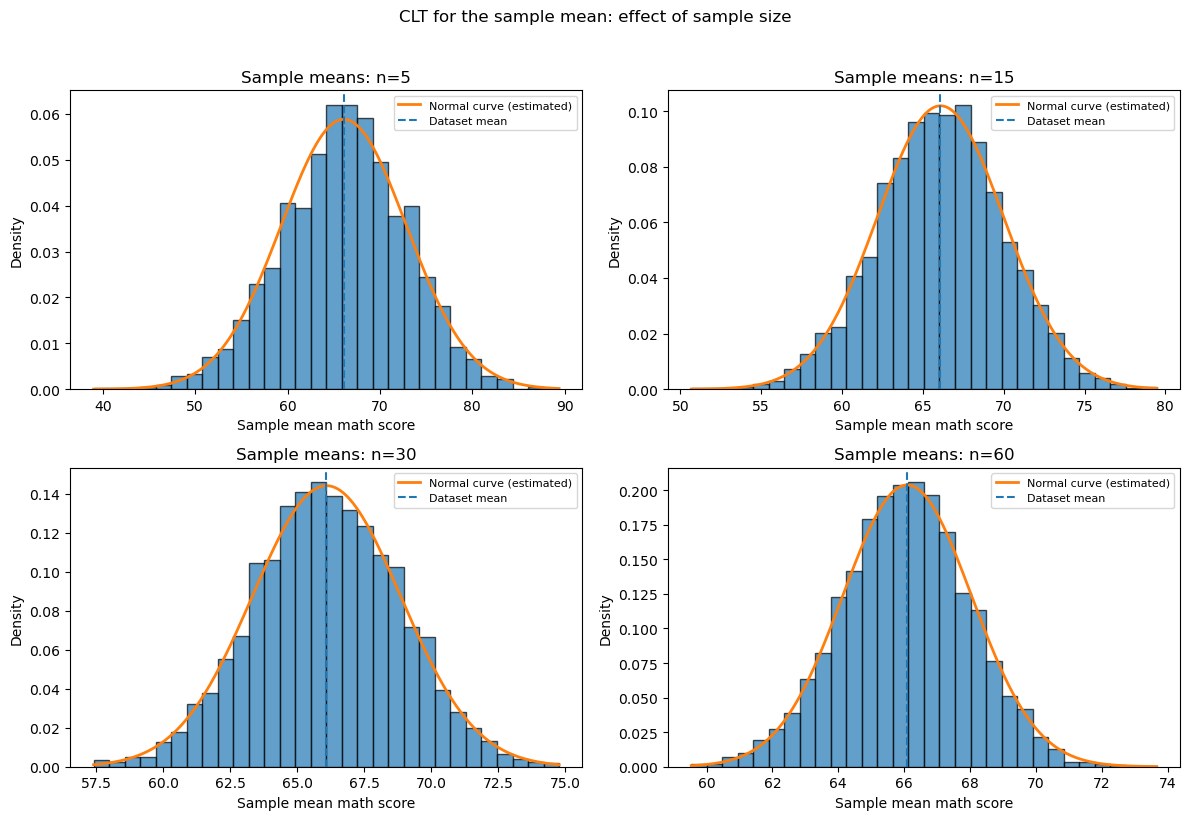

In [15]:
rng = np.random.default_rng(7)
score_population = math_scores.to_numpy()
sample_sizes = [5, 15, 30, 60]
repetitions = 4000

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, n in zip(axes.ravel(), sample_sizes):
    means = np.array([
        rng.choice(score_population, size=n, replace=True).mean()
        for _ in range(repetitions)
    ])
    ax.hist(means, bins=30, density=True, edgecolor="black", alpha=0.7)
    mu_est = score_population.mean()
    se_est = score_population.std(ddof=1) / np.sqrt(n)
    x = np.linspace(means.min(), means.max(), 300)
    ax.plot(x, stats.norm.pdf(x, loc=mu_est, scale=se_est),
            linewidth=2, label="Normal curve (estimated)")
    ax.axvline(mu_est, linestyle="--", label="Dataset mean")
    ax.set_title(f"Sample means: n={n}")
    ax.set_xlabel("Sample mean math score")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)

plt.suptitle("CLT for the sample mean: effect of sample size", y=1.02)
plt.tight_layout()
plt.show()

The simulation demonstrates that as sample size increases from 5 to 60, the sampling distribution of the sample mean becomes increasingly concentrated around the dataset mean of approximately 66. This occurs because the standard error decreases according to $$(\sigma/\sqrt{n})$$. The distributions also appear approximately normal, consistent with the Central Limit Theorem. Therefore, larger random samples generally provide more precise estimates of the population mean.

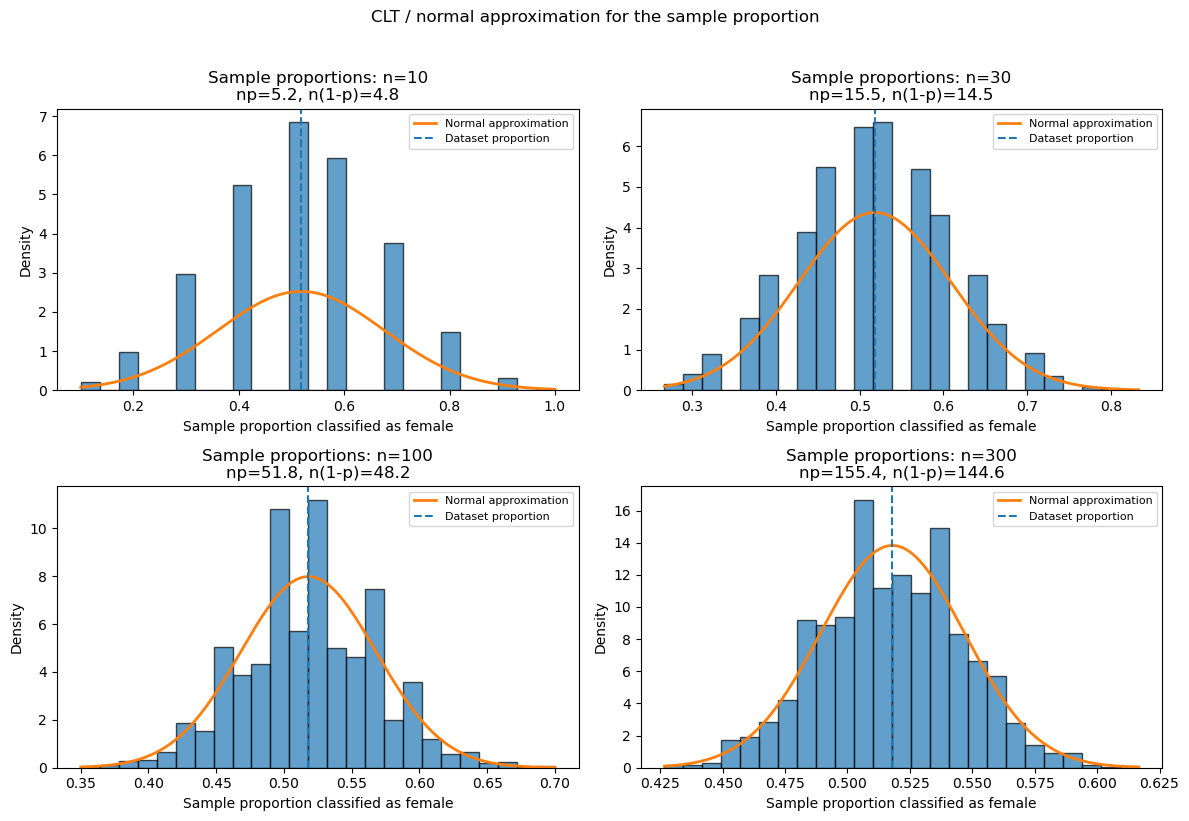

In [17]:
rng = np.random.default_rng(8)
binary_population = is_female.to_numpy()
p_est = binary_population.mean()
sample_sizes = [10, 30, 100, 300]
repetitions = 4000

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, n in zip(axes.ravel(), sample_sizes):
    proportions = np.array([
        rng.choice(binary_population, size=n, replace=True).mean()
        for _ in range(repetitions)
    ])
    ax.hist(proportions, bins=25, density=True, edgecolor="black", alpha=0.7)
    se_est = np.sqrt(p_est * (1 - p_est) / n)
    x = np.linspace(max(0, proportions.min()), min(1, proportions.max()), 300)
    if se_est > 0:
        ax.plot(x, stats.norm.pdf(x, loc=p_est, scale=se_est),
                linewidth=2, label="Normal approximation")
    ax.axvline(p_est, linestyle="--", label="Dataset proportion")
    ax.set_title(f"Sample proportions: n={n}\nnp={n*p_est:.1f}, n(1-p)={n*(1-p_est):.1f}")
    ax.set_xlabel("Sample proportion classified as female")
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)

plt.suptitle("CLT / normal approximation for the sample proportion", y=1.02)
plt.tight_layout()
plt.show()

Larger random samples provide more precise estimates of the population proportion, and when the required conditions are satisfied, the sampling distribution can be approximated by a normal distribution.

## 7. Confidence Intervals for Both Statistics

A **confidence interval (CI)** is a range of plausible values for a population parameter.

A 95% confidence procedure means that, over repeated samples, about 95% of the intervals constructed using that method would contain the true population parameter, assuming the method's conditions hold.

### A. Confidence Interval for the Population Mean

**1. When the population standard deviation ($\sigma$) is known:**

If normal-based inference is appropriate, use the $z$-interval:

$$
\bar{x} \pm z^* \frac{\sigma}{\sqrt{n}}
$$

**2. When the population standard deviation ($\sigma$) is unknown:**

Usually, $\sigma$ is unknown, so use the $t$-interval with the sample standard deviation ($s$):

$$
\bar{x} \pm t^* \frac{s}{\sqrt{n}}
$$

Where:
- $\bar{x}$ = sample mean
- $z^*$ = critical z-value
- $t^*$ = critical t-value
- $\sigma$ = population standard deviation
- $s$ = sample standard deviation
- $n$ = sample size

### B. Confidence Interval for the Population Proportion

A basic normal-approximation (Wald) confidence interval is:

$$
\hat{p} \pm z^* \sqrt{\frac{\hat{p}(1-\hat{p})}{n}}
$$

Where:
- $\hat{p}$ = sample proportion
- $z^*$ = critical z-value
- $n$ = sample size

**Important:** The Wald interval can perform poorly for small samples or proportions close to 0 or 1. A **Wilson interval** is often a better default.

### Example Using the Dataset

The next cell calculates:
- A 95% $t$-confidence interval for the mean math score.
- A 95% Wilson confidence interval for the proportion of records classified as female.

In [29]:
confidence = 0.95
alpha = 1 - confidence


n_m = len(math_scores)
mean_m = math_scores.mean()
sd_m = math_scores.std(ddof=1)
se_m = sd_m / np.sqrt(n_m)

# Mean: one-sample z interval (population SD known)
sigma = 15  # Example only; replace with the known population SD

z_star = stats.norm.ppf(1 - alpha / 2)
se_z = sigma / np.sqrt(n_m)

ci_mean_z = (
    mean_m - z_star * se_z,
    mean_m + z_star * se_z
)

print("95% z interval for population mean math score")
print(f"Population SD = {sigma}")
print(f"z critical = {z_star:.3f}")
print(f"CI = ({ci_mean_z[0]:.3f}, {ci_mean_z[1]:.3f})")

# Proportion: normal-approximation (Wald) interval

z_star = stats.norm.ppf(1 - alpha / 2)
se_prop = np.sqrt(phat * (1 - phat) / n_p)

ci_prop_z = (
    phat - z_star * se_prop,
    phat + z_star * se_prop
)

print("95% z interval for population proportion")
print(f"Sample proportion = {phat:.4f}")
print(f"Standard error = {se_prop:.4f}")
print(f"z critical = {z_star:.3f}")
print(f"CI = ({ci_prop_z[0]:.4f}, {ci_prop_z[1]:.4f})")


95% z interval for population mean math score
Population SD = 15
z critical = 1.960
CI = (65.159, 67.019)
95% z interval for population proportion
Sample proportion = 0.5180
Standard error = 0.0158
z critical = 1.960
CI = (0.4870, 0.5490)


In [37]:
# Mean: one-sample t interval
t_star = stats.t.ppf(1-alpha/2, df=n_m-1)
ci_mean = (mean_m-t_star*se_m, mean_m+t_star*se_m)

print("95% t interval for population mean math score")
print(f"n={n_m}, mean={mean_m:.3f}, sample SD={sd_m:.3f}, df={n_m-1}")
print(f"t critical={t_star:.3f}; CI=({ci_mean[0]:.3f}, {ci_mean[1]:.3f})")

# Proportion: Wilson interval, calculated directly (no extra package required)
x = int(is_female.sum())
n_p = len(is_female)
phat = x/n_p
z = stats.norm.ppf(1-alpha/2)
denom = 1 + z**2/n_p
center = (phat + z**2/(2*n_p))/denom
half = z*np.sqrt(phat*(1-phat)/n_p + z**2/(4*n_p**2))/denom
ci_prop = (center-half, center+half)


#The Wilson method generally performs better than the basic Wald interval, particularly with small samples or proportions close to 0 or 1.
#Interpretation:We are 95% confident that the calculated interval contains the true population proportion, assuming the sampling method and statistical conditions are appropriate.
print("95% Wilson interval for population proportion classified as female")
print(f"x={x}, n={n_p}, sample proportion={phat:.4f}")
print(f"CI=({ci_prop[0]:.4f}, {ci_prop[1]:.4f})")

95% t interval for population mean math score
n=1000, mean=66.089, sample SD=15.163, df=999
t critical=1.962; CI=(65.148, 67.030)
95% Wilson interval for population proportion classified as female
x=518, n=1000, sample proportion=0.5180
CI=(0.4870, 0.5488)


### Degrees of Freedom (df)

- `df` stands for degrees of freedom.
- For a one-sample t-interval:

  $$df = n - 1$$

- We subtract 1 because the sample mean is estimated from the same data, leaving `n - 1` degrees of freedom to estimate variability.

**Example:** If the sample contains 100 mathematics scores:

$$df = 100 - 1 = 99$$

### Why is the t-critical value 1.984 instead of 1.96?

For a 95% confidence interval with 99 degrees of freedom:

```python
t_star = stats.t.ppf(0.975, df=99)
```

- The critical t-value is approximately **1.984**.
- The corresponding z-critical value is approximately **1.96**.
- The t-distribution has heavier tails than the standard normal distribution when degrees of freedom are finite. Therefore, its critical value is slightly larger.

**Remember:** As the sample size increases, the t-distribution approaches the standard normal distribution, and the t-critical value approaches the z-critical value.


In [32]:
sample_sizes = [5, 10, 20, 30, 100, 500]
rows = []
for n in sample_sizes:
    rows.append({
        "n": n,
        "df = n - 1": n-1,
        "95% t critical": stats.t.ppf(0.975, df=n-1),
        "95% z critical": stats.norm.ppf(0.975)
    })
display(pd.DataFrame(rows).round(4))

,n,df = n - 1,95% t critical,95% z critical
0,5,4,2.7764,1.96
1,10,9,2.2622,1.96
2,20,19,2.0930,1.96
3,30,29,2.0452,1.96
4,100,99,1.9842,1.96
5,500,499,1.9647,1.96


## 8. Critical Values for Both Statistics

A **critical value** determines how many standard errors to move away from a sample statistic when constructing a confidence interval.

### Common Normal Critical Values

| Two-sided confidence level | Normal critical value ($z^*$) |
|---|---:|
| 90% | 1.645 |
| 95% | 1.960 |
| 99% | 2.576 |

### A. For the Sample Mean

- When the population standard deviation ($\sigma$) is known and normal-based inference is appropriate, use the **z-critical value**.
- When $\sigma$ is unknown, use the **t-critical value** with degrees of freedom:

$$
df=n-1
$$

### B. For the Sample Proportion

Use the **z-critical value** for the usual introductory normal-approximation interval, provided the conditions are satisfied.

Other methods, such as the **Wilson interval** or an exact binomial interval, can be used when appropriate. These methods do not use a t-critical value.

### Important Points

- Higher confidence level → larger critical value → wider confidence interval.
- Lower confidence level → smaller critical value → narrower confidence interval.
- A t-critical value depends on both the confidence level and the degrees of freedom.

In [35]:
levels = [0.90, 0.95, 0.99]
critical_table = []
for conf in levels:
    zcrit = stats.norm.ppf(1-(1-conf)/2)
    critical_table.append({"Confidence level": f"{conf:.0%}", "z critical": zcrit})
display(pd.DataFrame(critical_table).round(4))

n_small = 10
print(f"For a mean with n={n_small}, df={n_small-1}:")
print(f"95% z critical = {stats.norm.ppf(0.975):.3f}")
print(f"95% t critical = {stats.t.ppf(0.975, df=n_small-1):.3f}")

,Confidence level,z critical
0,90%,1.6449
1,95%,1.9600
2,99%,2.5758


For a mean with n=10, df=9:
95% z critical = 1.960
95% t critical = 2.262


## 10. Finite Population Correction (FPC)

When sampling **without replacement** from a known finite population, uncertainty decreases when the sample represents a substantial fraction of the population.

The Finite Population Correction factor is:

$$
FPC = \sqrt{\frac{N-n}{N-1}}
$$

where:
- $N$ = population size
- $n$ = sample size

### A. For the Sample Mean

The standard error with FPC is:

$$
SE_{\bar{X},FPC}
=
\frac{\sigma}{\sqrt{n}}
\sqrt{\frac{N-n}{N-1}}
$$

If the population standard deviation ($\sigma$) is unknown, use the sample standard deviation ($s$) to estimate it:

$$
\widehat{SE}_{\bar{X},FPC}
=
\frac{s}{\sqrt{n}}
\sqrt{\frac{N-n}{N-1}}
$$

### B. For the Sample Proportion

The standard error with FPC is:

$$
SE_{\hat{p},FPC}
=
\sqrt{\frac{p(1-p)}{n}}
\sqrt{\frac{N-n}{N-1}}
$$

If the population proportion ($p$) is unknown, use the sample proportion ($\hat{p}$) to estimate the standard error:

$$
\widehat{SE}_{\hat{p},FPC}
=
\sqrt{\frac{\hat{p}(1-\hat{p})}{n}}
\sqrt{\frac{N-n}{N-1}}
$$

### Example

Suppose the population size is $N=500$ and the sample size is $n=200$.

$$
FPC = \sqrt{\frac{500-200}{500-1}}
$$

$$
FPC = \sqrt{\frac{300}{499}} \approx 0.775
$$

The corrected standard error is approximately **77.5% of the uncorrected standard error**.

### Important Points

- A common rule of thumb is to consider FPC when the sampling fraction exceeds 5%:

$$
\frac{n}{N}>0.05
$$

- Larger sampling fractions produce a stronger correction and a smaller standard error.
- If $n=N$, then $FPC=0$, because the entire population has been observed.
- FPC reduces sampling uncertainty; it does not eliminate sampling bias.
- These formulas assume simple random sampling without replacement. Textbooks may use slightly different denominator conventions depending on how population variance is defined.

In [ ]:
N_population = 500
n_sample = 200
fpc = np.sqrt((N_population-n_sample)/(N_population-1))
print(f"Sampling fraction = {n_sample/N_population:.1%}")
print(f"FPC = {fpc:.4f}")

# Illustrative calculations using the available dataset's SD and proportion.
se_mean_uncorrected = math_scores.std(ddof=1)/np.sqrt(n_sample)
se_mean_corrected = se_mean_uncorrected*fpc
p_est = is_female.mean()
se_prop_uncorrected = np.sqrt(p_est*(1-p_est)/n_sample)
se_prop_corrected = se_prop_uncorrected*fpc

print(f"Mean SE: uncorrected={se_mean_uncorrected:.4f}, FPC-adjusted={se_mean_corrected:.4f}")
print(f"Proportion SE: uncorrected={se_prop_uncorrected:.4f}, FPC-adjusted={se_prop_corrected:.4f}")

## 11. Conditions for inference with SDSM (sample mean)

Check these before using a confidence interval or hypothesis test for a population mean:

1. **Randomness:** The sample is randomly selected, or the design otherwise supports the inference.
2. **Independence:** Observations are independent. For sampling without replacement, \(n\leq0.10N\) is a common approximation when using the usual SE without FPC.
3. **Normality or a sufficiently large sample:** A normal population gives an exactly normal sample mean under usual assumptions. For a non-normal population, the CLT can support an approximate normal sampling distribution for sufficiently large samples. Strong skewness and extreme outliers require care.
4. **Finite variance:** The usual CLT reasoning assumes finite population variance.
5. **Sampling design:** If a substantial fraction of a finite population is sampled without replacement, consider FPC.

A large sample does not fix selection bias or make a nonrepresentative sample representative.

## 12. Conditions for inference with SDSP (sample proportion)

Check these before using a confidence interval or hypothesis test for a population proportion:

1. **Binary outcome:** Each observation is clearly a success or failure for the characteristic.
2. **Randomness:** The sampling design supports inference about the target population.
3. **Independence:** Observations are independent, or the method accounts for dependence. For simple random sampling without replacement, \(n\leq0.10N\) is a common approximation when not using FPC.
4. **Success-failure condition:** For a normal approximation, check \(np\geq10\) and \(n(1-p)\geq10\). For confidence intervals, \(\hat p\) is commonly used as an estimate; for hypothesis tests, use the null value \(p_0\).
5. **Sampling design and FPC:** If sampling without replacement from a finite population and the sample fraction is substantial, account for the design and consider FPC.

If the normal approximation is poor, consider Wilson or exact binomial methods. A larger biased sample is still biased.

## 13. Simulating both sampling distributions side by side

This simulation repeatedly samples with replacement from the observations in `df`, using the observed data as an empirical stand-in for a population.

- The left plot shows repeated sample means of `math score`.
- The right plot shows repeated sample proportions classified as female.

**Limitation:** This is a learning simulation. It does not prove that the dataset is representative of a wider population.

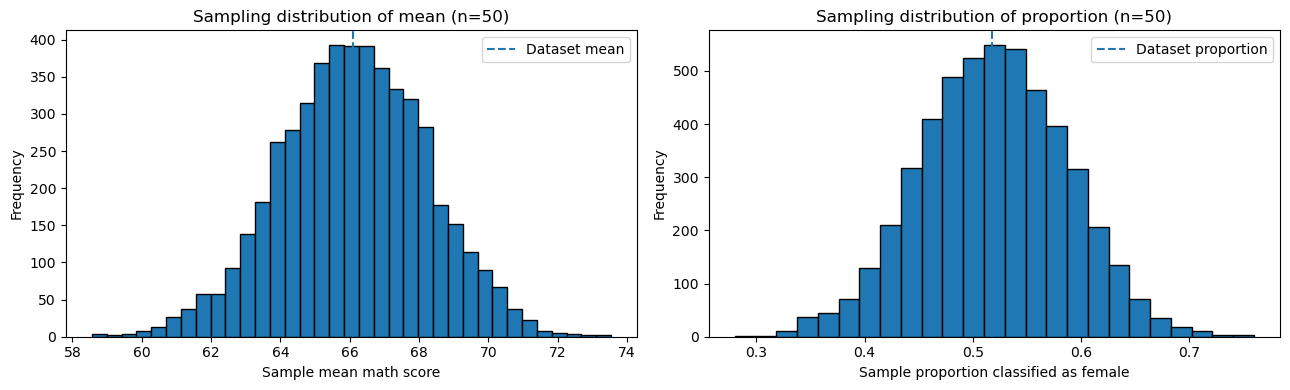

Mean of simulated means: 66.1151
SD of simulated means: 2.1267
Estimated SE of mean: 2.1444

Mean of simulated proportions: 0.5189
SD of simulated proportions: 0.0706
Estimated SE of proportion: 0.0707


In [39]:
rng = np.random.default_rng(2026)
n = 50
repetitions = 5000
scores = math_scores.to_numpy()
female = is_female.to_numpy()

sim_means = np.empty(repetitions)
sim_props = np.empty(repetitions)

for i in range(repetitions):
    sim_means[i] = rng.choice(scores, size=n, replace=True).mean()
    sim_props[i] = rng.choice(female, size=n, replace=True).mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(sim_means, bins=35, edgecolor="black")
axes[0].axvline(scores.mean(), linestyle="--", label="Dataset mean")
axes[0].set(title=f"Sampling distribution of mean (n={n})", xlabel="Sample mean math score", ylabel="Frequency")
axes[0].legend()

axes[1].hist(sim_props, bins=25, edgecolor="black")
axes[1].axvline(female.mean(), linestyle="--", label="Dataset proportion")
axes[1].set(title=f"Sampling distribution of proportion (n={n})", xlabel="Sample proportion classified as female", ylabel="Frequency")
axes[1].legend()
plt.tight_layout()
plt.show()

phat = female.mean()
print(f"Mean of simulated means: {sim_means.mean():.4f}")
print(f"SD of simulated means: {sim_means.std(ddof=1):.4f}")
print(f"Estimated SE of mean: {scores.std(ddof=1)/np.sqrt(n):.4f}")
print()
print(f"Mean of simulated proportions: {sim_props.mean():.4f}")
print(f"SD of simulated proportions: {sim_props.std(ddof=1):.4f}")
print(f"Estimated SE of proportion: {np.sqrt(phat*(1-phat)/n):.4f}")

## 14. Final Comparison and Self-Check

### Comparison: Sample Mean vs. Sample Proportion

| Concept | Sample Mean | Sample Proportion |
|---|---|---|
| Statistic | $\bar{x}$ | $\hat{p}=\frac{x}{n}$ |
| Population parameter | $\mu$ | $p$ |
| Center of sampling distribution | $\mu$ | $p$ |
| Standard error | $\frac{\sigma}{\sqrt{n}}$ | $\sqrt{\frac{p(1-p)}{n}}$ |
| Estimated standard error | $\frac{s}{\sqrt{n}}$ | $\sqrt{\frac{\hat{p}(1-\hat{p})}{n}}$ |
| Normality / CLT check | Population is normal or sample is sufficiently large, with assumptions satisfied | Sufficient expected successes and failures |
| Common confidence interval | *t*-interval if $\sigma$ is unknown | Normal-approximation or Wilson interval |
| Critical value | Usually $t^*$ if $\sigma$ is unknown; $z^*$ if known | Usually $z^*$ for normal approximation |
| Degrees of freedom | $n-1$ for one-sample *t*-inference | Not used in the usual one-proportion interval |
| Finite Population Correction (FPC) | Multiply SE by FPC when appropriate | Multiply SE by FPC when appropriate |

### Quick Self-Check

1. What is the difference between a sample distribution and a sampling distribution?
2. Why does standard error decrease as sample size increases?
3. Does the Central Limit Theorem (CLT) make individual observations normally distributed?
4. When do we use a *t*-critical value for a sample mean?
5. Why is a *t*-critical value not normally used for a sample proportion?
6. What does the 10% condition check?
7. When is the Finite Population Correction (FPC) useful?
8. Why can a large sample still be biased?

**Instructions:** Try answering these questions in your own words before moving on.